# Multiple Linear Regression on Dataset2 (Portugese Class)

$\textit{by Anmol Anand (MS24063)}$

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

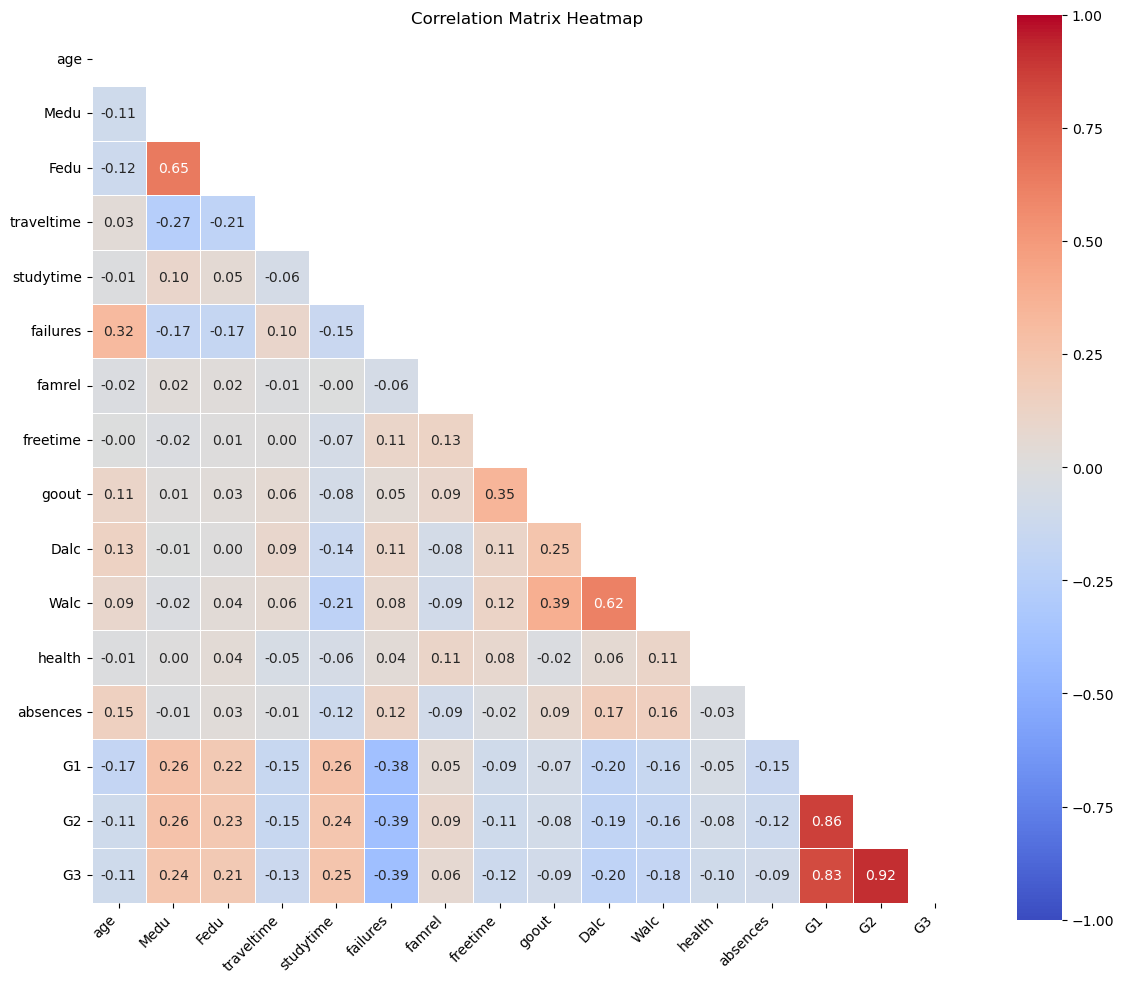

In [2]:
# Importing Data from csv file and Creating a correlation heatmap

df = pd.read_csv('student-por.csv', sep=';')
# print(df.head())

plt.figure(figsize=(12, 10))
corr_matrix = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",  # Good divergent color palette for negative (-1) to positive (+1) rules
    vmin=-1,
    vmax=1,  # Forces the color boundaries to represent true correlation limits
    center=0,  # Centers the neutral color at 0 (no correlation)
    square=True,  # Forces the grid cells to be perfectly square
    linewidths=0.5,  # Adds clean dividers between squares
)
plt.title("Correlation Matrix Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [3]:
# Creating the feature and the target arrays

feature_names = ['Medu', 'Fedu', 'studytime', 'failures', 'Dalc', 'Walc', 'G1', 'G2']
y = df["G3"].to_numpy()

X = []
for name in feature_names:
    X.append(df[name].to_numpy())
X = np.array(X).T
print(np.shape(X))

(649, 8)


In [4]:
# Shuffling and splitting the data into training and testing data
# Also choosing the model and training the model

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=62)

regressor = LinearRegression()
regressor.fit(X_train, y_train)
print("Coefficients:", regressor.coef_)
print("Intercept:", regressor.intercept_)

Coefficients: [-0.02086881  0.02271921  0.13560938 -0.19321827 -0.16024459  0.00889968
  0.14714044  0.87067587]
Intercept: 0.1385789264417383


In [5]:
# Comparing predictions against actual testing data
# Also computing the metrics for evaluation

predictions = regressor.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)
n = len(X)
p = len(X[0])
adj_r2 = 1-((1-r2)*(n-1)/(n-p-1))

print(f'MAE = {mae:.4f}')
print(f'RMSE = {rmse:.4f}')
print(f'R^2 = {r2:.4f}')
print(f'Adjusted R^2 = {adj_r2:.4f}')

MAE = 0.7785
RMSE = 1.2238
R^2 = 0.8534
Adjusted R^2 = 0.8515


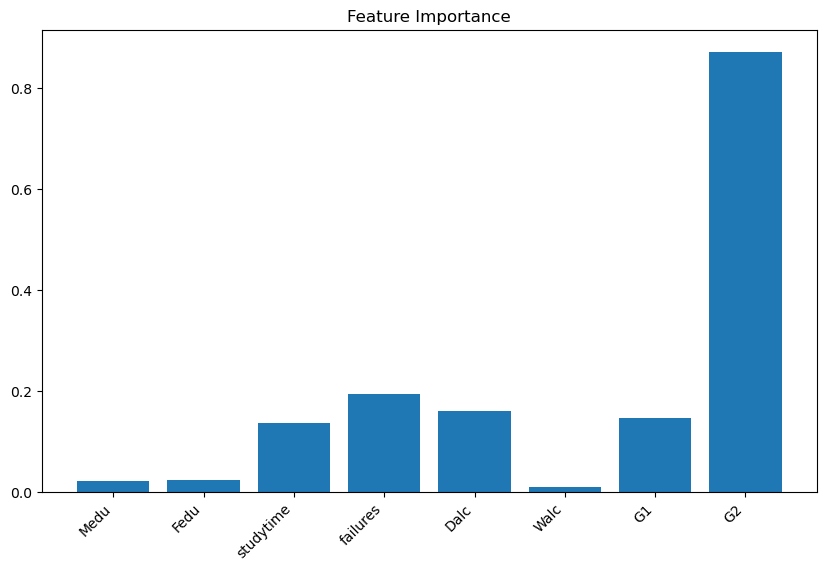

In [6]:
# Calculating feature importance and plotting it

importances = np.abs(regressor.coef_)
plt.figure(figsize=(10, 6))
plt.bar(feature_names, importances)
plt.title('Feature Importance')
plt.xticks(rotation=45, ha="right")
plt.show()

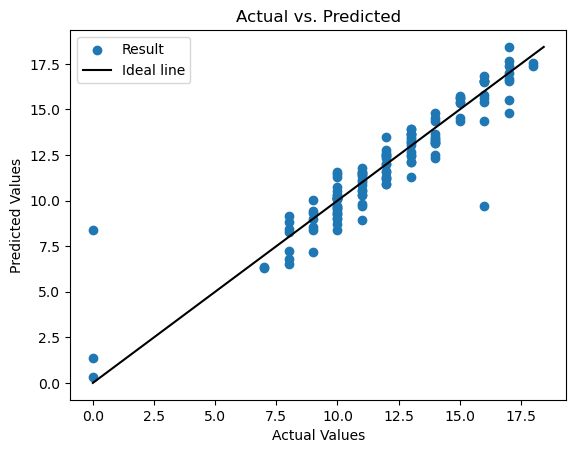

In [7]:
# Plotting the Predictions vs Reality graph

plt.scatter(y_test, predictions, label='Result')
min_val = min(min(y_test), min(predictions))
max_val = max(max(y_test), max(predictions))
plt.plot([min_val, max_val], [min_val, max_val], color = 'black', label='Ideal line')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted')
plt.legend()
plt.show()

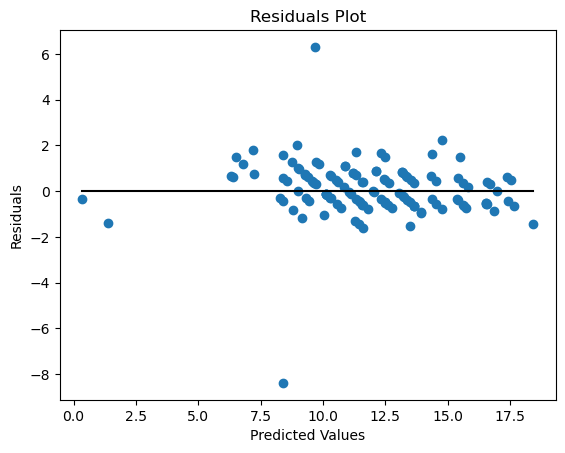

In [8]:
# Plotting residuals in order to check for any bias in the errors

residuals = y_test - predictions
plt.scatter(predictions, residuals)
plt.plot([min(predictions), max(predictions)], [0, 0], color='black')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals Plot')
plt.show()